# Rail Data - Initial Time Series EDA

This notebook loads the Supabase export and starts by understanding the data format, especially timestamp fields, before running a quick exploratory analysis.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

DATA_PATH = Path("../dataset/supabase/rail_data_rows_27march.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find dataset at: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)

# Drop columns not needed for analysis.
cols_to_drop = ["distance_from_origin_km", "created_at", "updated_at"]
df = df.drop(columns=cols_to_drop, errors="ignore")

print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {DATA_PATH}")
print(f"Dropped columns (if present): {cols_to_drop}")
df.head(10)

Loaded 30,799 rows and 10 columns from ..\dataset\supabase\rail_data_rows_27march.csv
Dropped columns (if present): ['distance_from_origin_km', 'created_at', 'updated_at']


,id,train_no,journey_date,station_code,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,delay_arrival_minutes,delay_departure_minutes
0,1,61631,2026-01-17,BPL,1768615200,1.768615e+09,NaN,1.768616e+09,NaN,10.0
1,2,61631,2026-01-17,SUW,1768616040,1.768616e+09,1.768616e+09,1.768617e+09,6.0,11.0
2,3,61631,2026-01-17,BVB,1768616640,1.768617e+09,NaN,1.768617e+09,NaN,6.0
3,4,61631,2026-01-17,DWG,1768617180,1.768617e+09,1.768618e+09,1.768618e+09,7.0,10.0
4,5,61631,2026-01-17,SMT,1768617720,1.768618e+09,1.768618e+09,1.768618e+09,10.0,12.0
5,6,61631,2026-01-17,SCI,1768618140,1.768618e+09,1.768619e+09,1.768619e+09,12.0,14.0
6,7,61631,2026-01-17,BHS,1768618800,1.768619e+09,1.768620e+09,1.768620e+09,14.0,17.0
7,8,61631,2026-01-17,SUMR,1768619880,1.768620e+09,1.768621e+09,1.768621e+09,16.0,20.0
8,9,61631,2026-01-17,GLG,1768620360,1.768620e+09,1.768621e+09,1.768622e+09,18.0,20.0
9,10,61631,2026-01-17,PAI,1768621080,1.768621e+09,1.768623e+09,1.768623e+09,26.0,31.0


In [2]:
# 1) Understand raw format after dropping non-analysis columns
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values (%):")
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing_pct.to_frame("missing_percent"))

# 2) Parse unix timestamp columns and convert them to IST as per schema definition.
unix_time_cols = [
    "scheduled_arrival",
    "scheduled_departure",
    "actual_arrival",
    "actual_departure",
]
unix_time_cols = [c for c in unix_time_cols if c in df.columns]

parse_rows = []
for c in unix_time_cols:
    parsed_utc = pd.to_datetime(df[c], unit="s", errors="coerce", utc=True)
    parsed_ist = parsed_utc.dt.tz_convert("Asia/Kolkata")

    df[f"{c}_ist"] = parsed_ist

    parse_rows.append(
        {
            "column": c,
            "valid_ratio": parsed_ist.notna().mean(),
            "nunique_timestamps": parsed_ist.nunique(dropna=True),
            "min_time_ist": parsed_ist.min(),
            "max_time_ist": parsed_ist.max(),
        }
    )

parse_report_df = pd.DataFrame(parse_rows)
if parse_report_df.empty:
    raise ValueError("No unix timestamp columns found for time-series analysis.")

parse_report_df = parse_report_df.sort_values(
    ["valid_ratio", "nunique_timestamps"],
    ascending=[False, False],
).reset_index(drop=True)

print("\nUnix timestamp parse quality (IST):")
display(parse_report_df)

# Prefer actual times first, then scheduled times for event-time axis.
preferred_time_cols = [
    "actual_departure",
    "actual_arrival",
    "scheduled_departure",
    "scheduled_arrival",
]
selected_base_col = None
for c in preferred_time_cols:
    hit = parse_report_df.loc[(parse_report_df["column"] == c) & (parse_report_df["valid_ratio"] > 0)]
    if not hit.empty:
        selected_base_col = c
        break
if selected_base_col is None:
    selected_base_col = parse_report_df.iloc[0]["column"]

time_col = f"{selected_base_col}_ist"
df["_event_time"] = df[time_col]
df = df.dropna(subset=["_event_time"]).sort_values("_event_time").reset_index(drop=True)

# Keep journey_date as date for grouping/reporting consistency.
if "journey_date" in df.columns:
    df["journey_date"] = pd.to_datetime(df["journey_date"], errors="coerce").dt.date

print(f"\nUsing '{selected_base_col}' converted to IST as time axis")
print(f"Valid timestamp rows: {len(df):,}")
print(f"Time range (IST): {df['_event_time'].min()} to {df['_event_time'].max()}")

print("\nParsed timestamp preview (IST):")
preview_cols = [c for c in ["train_no", "journey_date", "station_code", "_event_time"] if c in df.columns]
preview_cols += [f"{c}_ist" for c in unix_time_cols]
display(df[preview_cols].head(8))

# Gap diagnostics for time series cadence in IST event time.
time_gaps = df["_event_time"].diff().dropna()
if not time_gaps.empty:
    print("\nTypical time gap between consecutive records:")
    print(time_gaps.describe())

Column names:
['id', 'train_no', 'journey_date', 'station_code', 'scheduled_arrival', 'scheduled_departure', 'actual_arrival', 'actual_departure', 'delay_arrival_minutes', 'delay_departure_minutes']

Data types:


,dtype
id,int64
train_no,int64
journey_date,str
station_code,str
scheduled_arrival,int64
scheduled_departure,float64
actual_arrival,float64
actual_departure,float64
delay_arrival_minutes,float64
delay_departure_minutes,float64



Missing values (%):


,missing_percent
actual_departure,9.909413
delay_departure_minutes,9.909413
delay_arrival_minutes,3.487126
actual_arrival,3.477386
scheduled_departure,2.194876
id,0.000000
train_no,0.000000
scheduled_arrival,0.000000
journey_date,0.000000
station_code,0.000000



Unix timestamp parse quality (IST):


,column,valid_ratio,nunique_timestamps,min_time_ist,max_time_ist
0,scheduled_arrival,1.000000,26108,2026-01-17 07:30:00+05:30,2026-03-27 05:15:00+05:30
1,scheduled_departure,0.978051,25230,2026-01-17 07:30:00+05:30,2026-03-27 04:07:00+05:30
2,actual_arrival,0.965226,29658,2026-01-17 07:49:39+05:30,2026-03-27 05:16:12+05:30
3,actual_departure,0.900906,27680,2026-01-17 07:40:20+05:30,2026-03-27 04:47:10+05:30



Using 'actual_departure' converted to IST as time axis
Valid timestamp rows: 27,747
Time range (IST): 2026-01-17 07:40:20+05:30 to 2026-03-27 04:47:10+05:30

Parsed timestamp preview (IST):


,train_no,journey_date,station_code,_event_time,scheduled_arrival_ist,scheduled_departure_ist,actual_arrival_ist,actual_departure_ist
0,61631,2026-01-17,BPL,2026-01-17 07:40:20+05:30,2026-01-17 07:30:00+05:30,2026-01-17 07:30:00+05:30,NaT,2026-01-17 07:40:20+05:30
1,61631,2026-01-17,SUW,2026-01-17 07:56:15+05:30,2026-01-17 07:44:00+05:30,2026-01-17 07:45:00+05:30,2026-01-17 07:49:39+05:30,2026-01-17 07:56:15+05:30
2,61631,2026-01-17,BVB,2026-01-17 08:01:00+05:30,2026-01-17 07:54:00+05:30,2026-01-17 07:55:00+05:30,NaT,2026-01-17 08:01:00+05:30
3,61631,2026-01-17,DWG,2026-01-17 08:14:10+05:30,2026-01-17 08:03:00+05:30,2026-01-17 08:04:00+05:30,2026-01-17 08:10:22+05:30,2026-01-17 08:14:10+05:30
4,61631,2026-01-17,SMT,2026-01-17 08:24:52+05:30,2026-01-17 08:12:00+05:30,2026-01-17 08:13:00+05:30,2026-01-17 08:21:54+05:30,2026-01-17 08:24:52+05:30
5,61631,2026-01-17,SCI,2026-01-17 08:35:17+05:30,2026-01-17 08:19:00+05:30,2026-01-17 08:21:00+05:30,2026-01-17 08:31:26+05:30,2026-01-17 08:35:17+05:30
6,61631,2026-01-17,BHS,2026-01-17 08:49:12+05:30,2026-01-17 08:30:00+05:30,2026-01-17 08:32:00+05:30,2026-01-17 08:44:25+05:30,2026-01-17 08:49:12+05:30
7,61631,2026-01-17,SUMR,2026-01-17 09:08:52+05:30,2026-01-17 08:48:00+05:30,2026-01-17 08:49:00+05:30,2026-01-17 09:03:50+05:30,2026-01-17 09:08:52+05:30



Typical time gap between consecutive records:
count              27746
mean     0 days 00:03:34
std      0 days 00:03:22
min      0 days 00:00:00
25%      0 days 00:01:07
50%      0 days 00:02:38
75%      0 days 00:05:04
max      0 days 00:51:50
Name: _event_time, dtype: object


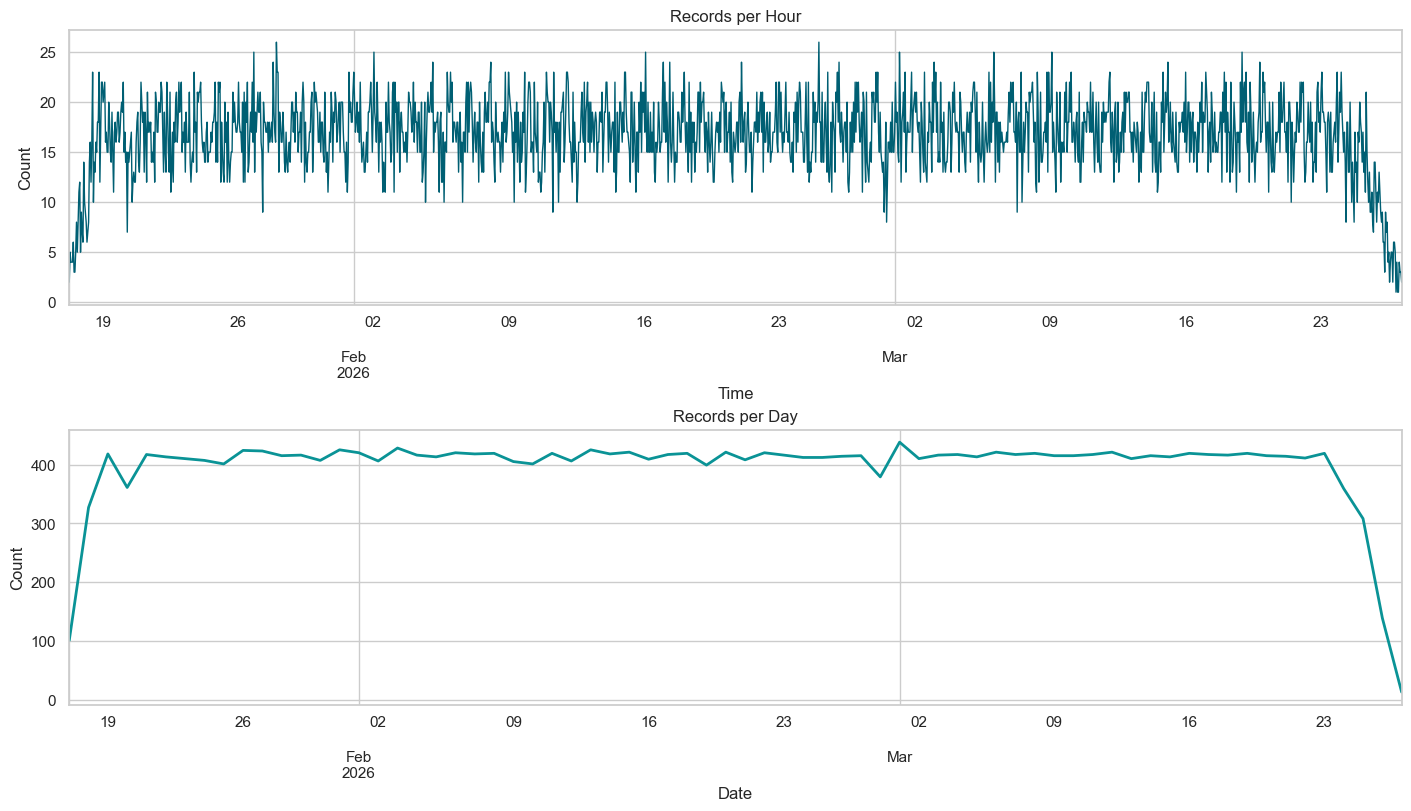

Hourly count summary:


,hourly_records
count,1654.000000
mean,16.775695
std,3.740346
min,1.000000
25%,15.000000
50%,17.000000
75%,19.000000
max,26.000000


Daily count summary:


,daily_records
count,70.000000
mean,396.385714
std,70.334870
min,13.000000
25%,409.250000
50%,415.000000
75%,419.000000
max,438.000000


Top 10 train_no by record count:


,records
train_no,
18237,5838
18238,5219
11077,4038
11078,3753
12137,3227
12138,2918
61632,1013
61631,970
11606,401


Sample records (post timestamp parsing/sorting):


,id,train_no,journey_date,station_code,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,delay_arrival_minutes,delay_departure_minutes,scheduled_arrival_ist,scheduled_departure_ist,actual_arrival_ist,actual_departure_ist,_event_time
0,1,61631,2026-01-17,BPL,1768615200,1.768615e+09,NaN,1.768616e+09,NaN,10.0,2026-01-17 07:30:00+05:30,2026-01-17 07:30:00+05:30,NaT,2026-01-17 07:40:20+05:30,2026-01-17 07:40:20+05:30
1,2,61631,2026-01-17,SUW,1768616040,1.768616e+09,1.768616e+09,1.768617e+09,6.0,11.0,2026-01-17 07:44:00+05:30,2026-01-17 07:45:00+05:30,2026-01-17 07:49:39+05:30,2026-01-17 07:56:15+05:30,2026-01-17 07:56:15+05:30
2,3,61631,2026-01-17,BVB,1768616640,1.768617e+09,NaN,1.768617e+09,NaN,6.0,2026-01-17 07:54:00+05:30,2026-01-17 07:55:00+05:30,NaT,2026-01-17 08:01:00+05:30,2026-01-17 08:01:00+05:30
3,4,61631,2026-01-17,DWG,1768617180,1.768617e+09,1.768618e+09,1.768618e+09,7.0,10.0,2026-01-17 08:03:00+05:30,2026-01-17 08:04:00+05:30,2026-01-17 08:10:22+05:30,2026-01-17 08:14:10+05:30,2026-01-17 08:14:10+05:30
4,5,61631,2026-01-17,SMT,1768617720,1.768618e+09,1.768618e+09,1.768618e+09,10.0,12.0,2026-01-17 08:12:00+05:30,2026-01-17 08:13:00+05:30,2026-01-17 08:21:54+05:30,2026-01-17 08:24:52+05:30,2026-01-17 08:24:52+05:30
5,6,61631,2026-01-17,SCI,1768618140,1.768618e+09,1.768619e+09,1.768619e+09,12.0,14.0,2026-01-17 08:19:00+05:30,2026-01-17 08:21:00+05:30,2026-01-17 08:31:26+05:30,2026-01-17 08:35:17+05:30,2026-01-17 08:35:17+05:30
6,7,61631,2026-01-17,BHS,1768618800,1.768619e+09,1.768620e+09,1.768620e+09,14.0,17.0,2026-01-17 08:30:00+05:30,2026-01-17 08:32:00+05:30,2026-01-17 08:44:25+05:30,2026-01-17 08:49:12+05:30,2026-01-17 08:49:12+05:30
7,8,61631,2026-01-17,SUMR,1768619880,1.768620e+09,1.768621e+09,1.768621e+09,16.0,20.0,2026-01-17 08:48:00+05:30,2026-01-17 08:49:00+05:30,2026-01-17 09:03:50+05:30,2026-01-17 09:08:52+05:30,2026-01-17 09:08:52+05:30
8,9,61631,2026-01-17,GLG,1768620360,1.768620e+09,1.768621e+09,1.768622e+09,18.0,20.0,2026-01-17 08:56:00+05:30,2026-01-17 08:58:00+05:30,2026-01-17 09:14:19+05:30,2026-01-17 09:18:24+05:30,2026-01-17 09:18:24+05:30
9,10,61631,2026-01-17,PAI,1768621080,1.768621e+09,1.768623e+09,1.768623e+09,26.0,31.0,2026-01-17 09:08:00+05:30,2026-01-17 09:09:00+05:30,2026-01-17 09:34:27+05:30,2026-01-17 09:39:49+05:30,2026-01-17 09:39:49+05:30


In [3]:
# 3) Initial EDA for time series behavior
# Aggregate record counts by hour/day to inspect data density.
hourly_counts = (
    df.set_index("_event_time")
      .resample("1h")
      .size()
      .rename("records")
)

daily_counts = (
    df.set_index("_event_time")
      .resample("1D")
      .size()
      .rename("records")
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)

hourly_counts.plot(ax=axes[0], color="#005f73", linewidth=1)
axes[0].set_title("Records per Hour")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Count")

daily_counts.plot(ax=axes[1], color="#0a9396", linewidth=2)
axes[1].set_title("Records per Day")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Count")

plt.show()

print("Hourly count summary:")
display(hourly_counts.describe().to_frame("hourly_records"))

print("Daily count summary:")
display(daily_counts.describe().to_frame("daily_records"))

# Optional: If key identifiers exist, quickly inspect top entities.
possible_id_cols = ["train_no", "train_id", "journey_id", "trip_id", "vehicle_id", "train_number"]
available_id_cols = [c for c in possible_id_cols if c in df.columns]

if available_id_cols:
    id_col = available_id_cols[0]
    print(f"Top 10 {id_col} by record count:")
    display(df[id_col].value_counts().head(10).to_frame("records"))
else:
    print("No standard train/journey identifier column found for top-entity analysis.")

print("Sample records (post timestamp parsing/sorting):")
display(df.head(15))

## Train 12138 - Weekly Station vs Departure Delay

Overlay departure-delay curves for each journey date in one week, using station sequence on x-axis.

Raw CSV row check:


,id,train_no,journey_date,station_code,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,delay_arrival_minutes,delay_departure_minutes
28613,28615,12138,2026-03-20,MAUR,1774032540,1.774033e+09,1.774033e+09,1.774033e+09,4.0,8.0


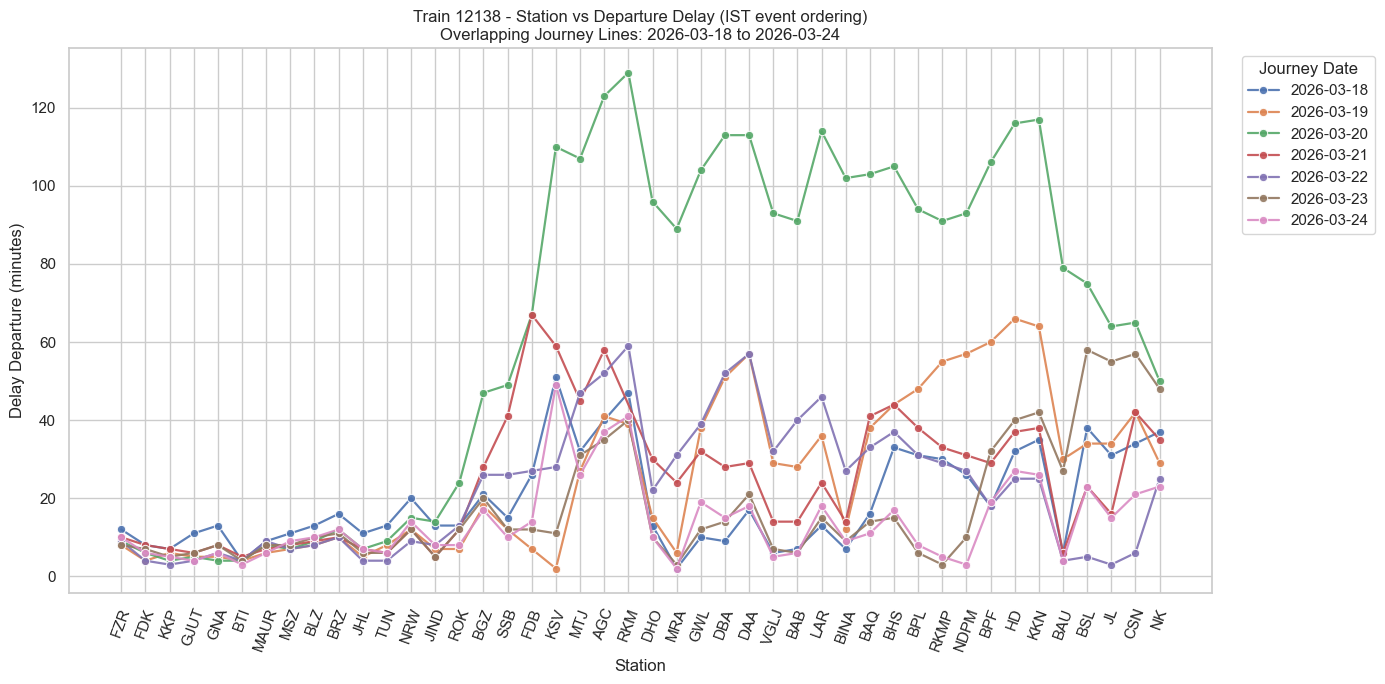

Plotted week: 2026-03-18 to 2026-03-24
Journeys in plot: 7
Stations in plot: 44

Debug check inside plotting frame (id=28615):


,journey_date,station_code,delay_departure_minutes,id
25690,2026-03-20,MAUR,8.0,28615


,journey_date,station_code,delay_departure_minutes,id
24807,2026-03-18,FZR,12.0,27689
24822,2026-03-18,FDK,8.0,27690
24828,2026-03-18,KKP,7.0,27691
24835,2026-03-18,GJUT,11.0,27692
24839,2026-03-18,GNA,13.0,27693
24848,2026-03-18,BTI,4.0,27694
24860,2026-03-18,MAUR,9.0,27695
24867,2026-03-18,MSZ,11.0,27696
24872,2026-03-18,BLZ,13.0,27697
24877,2026-03-18,BRZ,16.0,27698


In [4]:
# Weekly overlapping lines: station_code vs delay_departure_minutes for train 12138
# Debug and fix: use journey_date from CSV as journey key (not event-date derived key).
train_no_target = 12138
debug_id = 28615

required_cols = ["id", "train_no", "journey_date", "station_code", "delay_departure_minutes", "_event_time"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

# Debug against raw CSV row.
raw_df = pd.read_csv(DATA_PATH)
raw_debug = raw_df.loc[raw_df["id"] == debug_id, [
    "id", "train_no", "journey_date", "station_code",
    "scheduled_arrival", "scheduled_departure", "actual_arrival", "actual_departure",
    "delay_arrival_minutes", "delay_departure_minutes"
]]
print("Raw CSV row check:")
display(raw_debug)

plot_df = df[df["train_no"] == train_no_target].copy()
plot_df = plot_df.dropna(subset=["delay_departure_minutes", "station_code", "_event_time", "journey_date"])

if plot_df.empty:
    raise ValueError(f"No rows available for train_no={train_no_target} after filtering.")

# Ensure journey_date is the true journey key from source data.
plot_df["journey_date"] = pd.to_datetime(plot_df["journey_date"], errors="coerce").dt.date
plot_df = plot_df.dropna(subset=["journey_date"])

# Pick latest 7 journey dates for this train.
latest_journey_date = plot_df["journey_date"].max()
week_start = latest_journey_date - pd.Timedelta(days=6)
week_mask = (plot_df["journey_date"] >= week_start) & (plot_df["journey_date"] <= latest_journey_date)
week_df = plot_df.loc[week_mask].copy()

if week_df.empty:
    raise ValueError("No records found in selected 7-day journey window for train 12138.")

# If duplicate station entries exist for same journey, keep the latest record by id.
week_df = week_df.sort_values(["journey_date", "station_code", "id"])
week_df = week_df.drop_duplicates(subset=["journey_date", "station_code"], keep="last")

# Use median event-time order per station as x-axis ordering for consistent overlap.
station_order = (
    week_df.groupby("station_code")["_event_time"]
    .median()
    .sort_values()
    .index
    .tolist()
)

week_df["station_code"] = pd.Categorical(week_df["station_code"], categories=station_order, ordered=True)
journey_station_delay = week_df.sort_values(["journey_date", "station_code"])[
    ["journey_date", "station_code", "delay_departure_minutes", "id"]
].copy()

plt.figure(figsize=(14, 7))
sns.lineplot(
    data=journey_station_delay,
    x="station_code",
    y="delay_departure_minutes",
    hue="journey_date",
    marker="o",
    linewidth=1.6,
    alpha=0.9,
)

plt.title(
    f"Train {train_no_target} - Station vs Departure Delay (IST event ordering)\n"
    f"Overlapping Journey Lines: {week_start} to {latest_journey_date}"
)
plt.xlabel("Station")
plt.ylabel("Delay Departure (minutes)")
plt.xticks(rotation=70)
plt.legend(title="Journey Date", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"Plotted week: {week_start} to {latest_journey_date}")
print(f"Journeys in plot: {journey_station_delay['journey_date'].nunique()}")
print(f"Stations in plot: {journey_station_delay['station_code'].nunique()}")

print("\nDebug check inside plotting frame (id=28615):")
display(journey_station_delay.loc[journey_station_delay["id"] == debug_id])

display(journey_station_delay.head(20))

## Train 12138 - Monthly Interactive Station Delay View

Interactive Plotly chart for a 30-day window with one trace per journey date (legend toggle enabled).

In [ ]:
# Monthly interactive lines (30-day window): station_code vs delay_departure_minutes for train 12138
import json
import plotly.express as px

train_no_target = 12138
required_cols = ["id", "train_no", "journey_date", "station_code", "delay_departure_minutes", "_event_time"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

# Reference halt sequence from static train route JSON.
STATIC_ROUTE_PATH = Path("../docs/statics/12138_static.json")
if not STATIC_ROUTE_PATH.exists():
    raise FileNotFoundError(f"Static route file not found: {STATIC_ROUTE_PATH.resolve()}")

with open(STATIC_ROUTE_PATH, "r", encoding="utf-8") as f:
    static_json = json.load(f)

route_rows = static_json.get("data", {}).get("route", [])
halt_route = [r for r in route_rows if int(r.get("isHalt", 0)) == 1]
halt_station_order_full = [r.get("stationCode") for r in sorted(halt_route, key=lambda x: x.get("sequence", 10**9)) if r.get("stationCode")]

if not halt_station_order_full:
    raise ValueError("No halt stations found in static route JSON.")

month_df = df[df["train_no"] == train_no_target].copy()
month_df = month_df.dropna(subset=["delay_departure_minutes", "station_code", "_event_time", "journey_date"])

if month_df.empty:
    raise ValueError(f"No rows available for train_no={train_no_target} after filtering.")

# Keep journey_date from source as the true journey key.
month_df["journey_date"] = pd.to_datetime(month_df["journey_date"], errors="coerce").dt.date
month_df = month_df.dropna(subset=["journey_date"])

latest_journey_date = month_df["journey_date"].max()
month_start = latest_journey_date - pd.Timedelta(days=29)
month_mask = (month_df["journey_date"] >= month_start) & (month_df["journey_date"] <= latest_journey_date)
month_df = month_df.loc[month_mask].copy()

if month_df.empty:
    raise ValueError("No records found in selected 30-day journey window for train 12138.")

# Ignore intermediate stations (isHalt=0) by keeping only halt stations from static route.
month_df = month_df[month_df["station_code"].isin(halt_station_order_full)].copy()

if month_df.empty:
    raise ValueError("No halt-station records available in the selected month window.")

# Keep latest row for duplicate journey_date + station_code combinations.
month_df = month_df.sort_values(["journey_date", "station_code", "id"])
month_df = month_df.drop_duplicates(subset=["journey_date", "station_code"], keep="last")

# Use static halt sequence as the x-axis order.
present_halts = set(month_df["station_code"].unique())
station_order = [s for s in halt_station_order_full if s in present_halts]
missing_halts_in_month = [s for s in halt_station_order_full if s not in present_halts]

month_plot = month_df[["journey_date", "station_code", "delay_departure_minutes", "id"]].copy()
month_plot["station_code"] = pd.Categorical(month_plot["station_code"], categories=station_order, ordered=True)
month_plot = month_plot.sort_values(["journey_date", "station_code"])
month_plot["journey_date"] = month_plot["journey_date"].astype(str)

fig = px.line(
    month_plot,
    x="station_code",
    y="delay_departure_minutes",
    color="journey_date",
    markers=True,
    category_orders={"station_code": station_order},
    title=(
        f"Train {train_no_target} - Halt Station vs Departure Delay (30 Days)"
        f"<br><sup>Journey dates: {month_start} to {latest_journey_date}</sup>"
    ),
    labels={
        "station_code": "Station (halt-only, static route order)",
        "delay_departure_minutes": "Delay Departure (minutes)",
        "journey_date": "Journey Date",
    },
    hover_data={"id": True},
)

fig.update_layout(
    template="plotly_white",
    height=650,
    legend_title_text="Journey Date (click to toggle)",
)
fig.update_xaxes(tickangle=70)
fig.show()

print(f"Plotted month: {month_start} to {latest_journey_date}")
print(f"Journeys in plot: {month_plot['journey_date'].nunique()}")
print(f"Halt stations plotted: {month_plot['station_code'].nunique()} / {len(halt_station_order_full)} in static route")
print(f"Missing halt stations in selected month window: {len(missing_halts_in_month)}")
if missing_halts_in_month:
    print(missing_halts_in_month)

display(month_plot.head(20))

Plotted month: 2026-02-23 to 2026-03-24
Journeys in plot: 30
Halt stations plotted: 44 / 52 in static route
Missing halt stations in selected month window: 8
['DKZ', 'NDLS', 'ET', 'KNW', 'MMR', 'KYN', 'DR', 'CSMT']


,journey_date,station_code,delay_departure_minutes,id
15271,2026-02-23,FZR,9.0,17125
15282,2026-02-23,FDK,7.0,17126
15290,2026-02-23,KKP,9.0,17127
15296,2026-02-23,GJUT,10.0,17128
15301,2026-02-23,GNA,13.0,17129
15308,2026-02-23,BTI,4.0,17130
15319,2026-02-23,MAUR,10.0,17131
15325,2026-02-23,MSZ,11.0,17132
15329,2026-02-23,BLZ,12.0,17133
15336,2026-02-23,BRZ,13.0,17134


In [7]:
# Train 61632 - Monthly interactive halt-only station delay view
import json
import plotly.express as px

train_no_target = 61632
required_cols = ["id", "train_no", "journey_date", "station_code", "delay_departure_minutes", "_event_time"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

# Halt-only sequence from static route JSON for 61632.
STATIC_ROUTE_PATH = Path("../docs/statics/61632_static.json")
if not STATIC_ROUTE_PATH.exists():
    raise FileNotFoundError(f"Static route file not found: {STATIC_ROUTE_PATH.resolve()}")

with open(STATIC_ROUTE_PATH, "r", encoding="utf-8") as f:
    static_json = json.load(f)

route_rows = static_json.get("data", {}).get("route", [])
halt_route = [r for r in route_rows if int(r.get("isHalt", 0)) == 1]
halt_station_order_full = [
    r.get("stationCode")
    for r in sorted(halt_route, key=lambda x: x.get("sequence", 10**9))
    if r.get("stationCode")
]

if not halt_station_order_full:
    raise ValueError("No halt stations found in static route JSON for 61632.")

month_df = df[df["train_no"] == train_no_target].copy()
month_df = month_df.dropna(subset=["delay_departure_minutes", "station_code", "_event_time", "journey_date"])

if month_df.empty:
    raise ValueError(f"No rows available for train_no={train_no_target} after filtering.")

month_df["journey_date"] = pd.to_datetime(month_df["journey_date"], errors="coerce").dt.date
month_df = month_df.dropna(subset=["journey_date"])

latest_journey_date = month_df["journey_date"].max()
month_start = latest_journey_date - pd.Timedelta(days=29)
month_mask = (month_df["journey_date"] >= month_start) & (month_df["journey_date"] <= latest_journey_date)
month_df = month_df.loc[month_mask].copy()

if month_df.empty:
    raise ValueError("No records found in selected 30-day journey window for train 61632.")

# Ignore intermediate stations (isHalt=0).
month_df = month_df[month_df["station_code"].isin(halt_station_order_full)].copy()

if month_df.empty:
    raise ValueError("No halt-station records available in selected month window for 61632.")

# Keep latest row for duplicate journey_date + station_code combinations.
month_df = month_df.sort_values(["journey_date", "station_code", "id"])
month_df = month_df.drop_duplicates(subset=["journey_date", "station_code"], keep="last")

present_halts = set(month_df["station_code"].unique())
station_order = [s for s in halt_station_order_full if s in present_halts]
missing_halts_in_month = [s for s in halt_station_order_full if s not in present_halts]

month_plot = month_df[["journey_date", "station_code", "delay_departure_minutes", "id"]].copy()
month_plot["station_code"] = pd.Categorical(month_plot["station_code"], categories=station_order, ordered=True)
month_plot = month_plot.sort_values(["journey_date", "station_code"])
month_plot["journey_date"] = month_plot["journey_date"].astype(str)

fig = px.line(
    month_plot,
    x="station_code",
    y="delay_departure_minutes",
    color="journey_date",
    markers=True,
    category_orders={"station_code": station_order},
    title=(
        f"Train {train_no_target} - Halt Station vs Departure Delay (30 Days)"
        f"<br><sup>Journey dates: {month_start} to {latest_journey_date}</sup>"
    ),
    labels={
        "station_code": "Station (halt-only, static route order)",
        "delay_departure_minutes": "Delay Departure (minutes)",
        "journey_date": "Journey Date",
    },
    hover_data={"id": True},
)

fig.update_layout(
    template="plotly_white",
    height=650,
    legend_title_text="Journey Date (click to toggle)",
)
fig.update_xaxes(tickangle=70)
fig.show()

print(f"Plotted month: {month_start} to {latest_journey_date}")
print(f"Journeys in plot: {month_plot['journey_date'].nunique()}")
print(f"Halt stations plotted: {month_plot['station_code'].nunique()} / {len(halt_station_order_full)} in static route")
print(f"Missing halt stations in selected month window: {len(missing_halts_in_month)}")
if missing_halts_in_month:
    print(missing_halts_in_month)

display(month_plot.head(20))

Plotted month: 2026-02-25 to 2026-03-26
Journeys in plot: 30
Halt stations plotted: 15 / 16 in static route
Missing halt stations in selected month window: 1
['BPL']


,journey_date,station_code,delay_departure_minutes,id
16019,2026-02-25,BINA,6.0,17492
16022,2026-02-25,KIKA,2.0,17493
16027,2026-02-25,MABA,6.0,17494
16032,2026-02-25,KAH,3.0,17495
16037,2026-02-25,BET,5.0,17496
16040,2026-02-25,BAQ,17.0,17497
16045,2026-02-25,PAI,18.0,17498
16047,2026-02-25,GLG,18.0,17499
16050,2026-02-25,SUMR,17.0,17500
16057,2026-02-25,BHS,25.0,17501
